**과제 (강의자료 Ch6 p23, p41, Homework)**
- Example 6.5: Windy Gridworld
    - Solve Exercise 6.9, 6.10
- Example 6.6: Cliff Walking
    - Solve Exercise 6.11, 6.12

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
os.makedirs('figures', exist_ok=True)

ALPHA, EPSILON, GAMMA = 0.5, 0.1, 1.0     # Example 6.5
MAX_TIME_STEPS = 8000
N_SEEDS = 10                              # 결과를 시드 10개로 평균

**Example 6.5: Windy Gridworld** (교재 p.130)

- 7×10 격자, 시작 S=(3,0), 목표 G=(3,7), 열별 바람 [0,0,0,1,1,1,2,2,1,0] (위로 밀어 올림)
- 매 스텝 보상 −1, $\gamma=1$
- Exercise 6.9: 대각선 포함 8방향(King's moves), 그리고 제자리를 추가한 9방향
- Exercise 6.10: 바람이 있는 열에서 바람 세기가 1/3씩 −1, 0, +1 만큼 무작위로 변한다.

**구현 방법**: Ex 6.9, 6.10을 행동 집합과 바람 종류만 인자로 받는 make_windy_env 하나로 합쳤다. (같은 코드로 비교하기 위해)

In [2]:
ROWS, COLS = 7, 10
START, GOAL = (3, 0), (3, 7)
WIND = np.array([0, 0, 0, 1, 1, 1, 2, 2, 1, 0])

MOVES_4 = [(-1, 0), (1, 0), (0, -1), (0, 1)]                                  # up, down, left, right
MOVES_8 = MOVES_4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]                     # + 대각선 (King's moves)
MOVES_9 = MOVES_8 + [(0, 0)]                                                 # + 제자리

def make_windy_env(moves, stochastic=False):
    def step(state, action, rng):
        row, col = state
        dr, dc = moves[action]
        wind = WIND[col]
        if stochastic and wind > 0:                 # Ex 6.10: 바람이 있는 열에서만 -1/0/+1
            wind += rng.integers(-1, 2)
        new_row = int(np.clip(row + dr - wind, 0, ROWS - 1))
        new_col = int(np.clip(col + dc, 0, COLS - 1))
        return (new_row, new_col), -1.0
    return step, len(moves)

ENVS = {
    '4 moves (Ex 6.5)':          make_windy_env(MOVES_4),
    "King's 8 moves (Ex 6.9)":   make_windy_env(MOVES_8),
    "King's + no-move (Ex 6.9)": make_windy_env(MOVES_9),
    'Stochastic wind (Ex 6.10)': make_windy_env(MOVES_8, stochastic=True),
}

**세 가지 TD 제어 알고리즘**

- Sarsa: $R+\gamma Q(S',A')$ 
- Q-learning: $R+\gamma\max_a Q(S',a)$ 
- Expected Sarsa: $R+\gamma\sum_a\pi(a|S')Q(S',a)$
- 8,000 time step 동안 학습하고 매 스텝 지금까지 끝낸 에피소드 수를 기록한다 (Figure 6.3 형식)

In [3]:
def epsilon_greedy(q_values, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(len(q_values)))
    best = np.flatnonzero(q_values == q_values.max())       # 동점이면 무작위 
    return int(rng.choice(best))

def expected_q(q_values, eps):
    best = np.flatnonzero(q_values == q_values.max())
    probs = np.full(len(q_values), eps / len(q_values))
    probs[best] += (1.0 - eps) / len(best)
    return float(probs @ q_values)

def train(step, n_actions, algorithm, seed, eps=EPSILON, max_steps=MAX_TIME_STEPS,
          start=START, goal=GOAL, shape=(ROWS, COLS)):
    rng = np.random.default_rng(seed)
    Q = np.zeros(shape + (n_actions,))
    history, episodes, t = [], 0, 0
    while t < max_steps:
        state = start
        if algorithm == 'sarsa':
            action = epsilon_greedy(Q[state], eps, rng)            
        while state != goal and t < max_steps:
            if algorithm != 'sarsa':
                action = epsilon_greedy(Q[state], eps, rng)        
            next_state, reward = step(state, action, rng)
            if algorithm == 'sarsa' and next_state != goal:
                next_action = epsilon_greedy(Q[next_state], eps, rng)  
            if next_state == goal:
                target = reward                                  
            elif algorithm == 'sarsa':
                target = reward + GAMMA * Q[next_state][next_action]
            elif algorithm == 'q_learning':
                target = reward + GAMMA * Q[next_state].max()
            elif algorithm == 'expected_sarsa':
                target = reward + GAMMA * expected_q(Q[next_state], eps)
            Q[state][action] += ALPHA * (target - Q[state][action])
            state = next_state
            if algorithm == 'sarsa' and state != goal:
                action = next_action
            t += 1
            if state == goal:
                episodes += 1
            history.append(episodes)
    return Q, np.array(history)

def greedy_path(Q, step, rng, max_len=100):
    # 탐험 없이 greedy로 따라간 경로. max_len 안에 G에 못 가면 실패
    state, path = START, [START]
    for _ in range(max_len):
        if state == GOAL:
            break
        best = np.flatnonzero(Q[state] == Q[state].max())
        state, _ = step(state, int(best[0]), rng)
        path.append(state)
    return path

**실험**: 4개 환경 × 3개 알고리즘 × 10개 시드

- 학습 곡선 (time steps vs episodes)
- 마지막 2,000 스텝의 평균 에피소드 길이 (ε 탐험 포함)
- 학습된 greedy 정책의 경로 길이 ; 100 스텝 안에 G에 못 가면 실패로 세고, 중앙값과 도달 비율을 기록한다.

In [4]:
ALGOS = {'sarsa': 'Sarsa', 'q_learning': 'Q-learning', 'expected_sarsa': 'Expected Sarsa'}
results = {}
t0 = time.time()
for env_name, (step, n_actions) in ENVS.items():
    for algo in ALGOS:
        curves, ep_len, greedy_len = [], [], []
        for seed in range(N_SEEDS):
            Q, hist = train(step, n_actions, algo, seed)
            curves.append(hist)
            done = hist[-1] - hist[-2001]
            ep_len.append(2000 / max(done, 1))
            g = np.random.default_rng(1000 + seed)
            for _ in range(200 if 'Stochastic' in env_name else 1):
                path = greedy_path(Q, step, g)
                greedy_len.append(len(path) - 1 if path[-1] == GOAL else np.nan)   # 실패는 NaN
        gl = np.array(greedy_len)
        results[(env_name, algo)] = (np.mean(curves, axis=0), np.mean(ep_len),
                                     (np.nanmedian(gl), np.mean(~np.isnan(gl)) * 100), Q)
print(f'done in {time.time()-t0:.1f}s\n')

print(f"{'environment':28s} {'algorithm':15s} {'episodes@8000':>13s} {'avg ep len (last 2k)':>21s} {'greedy len (median)':>20s} {'reach G':>8s}")
for (env_name, algo), (curve, ep_len, (gl, ok), _) in results.items():
    print(f'{env_name:28s} {ALGOS[algo]:15s} {curve[-1]:13.1f} {ep_len:21.1f} {gl:20.1f} {ok:7.0f}%')

done in 25.3s

environment                  algorithm       episodes@8000  avg ep len (last 2k)  greedy len (median)  reach G
4 moves (Ex 6.5)             Sarsa                   161.4                  25.2                 16.0      40%
4 moves (Ex 6.5)             Q-learning              208.1                  18.8                 15.0     100%
4 moves (Ex 6.5)             Expected Sarsa          198.8                  20.0                 15.0     100%
King's 8 moves (Ex 6.9)      Sarsa                   238.1                  15.1                  7.0      80%
King's 8 moves (Ex 6.9)      Q-learning              333.5                  10.3                  7.0     100%
King's 8 moves (Ex 6.9)      Expected Sarsa          337.6                   9.9                  7.0     100%
King's + no-move (Ex 6.9)    Sarsa                   189.0                  19.4                  7.0      60%
King's + no-move (Ex 6.9)    Q-learning              266.4                  12.2                 

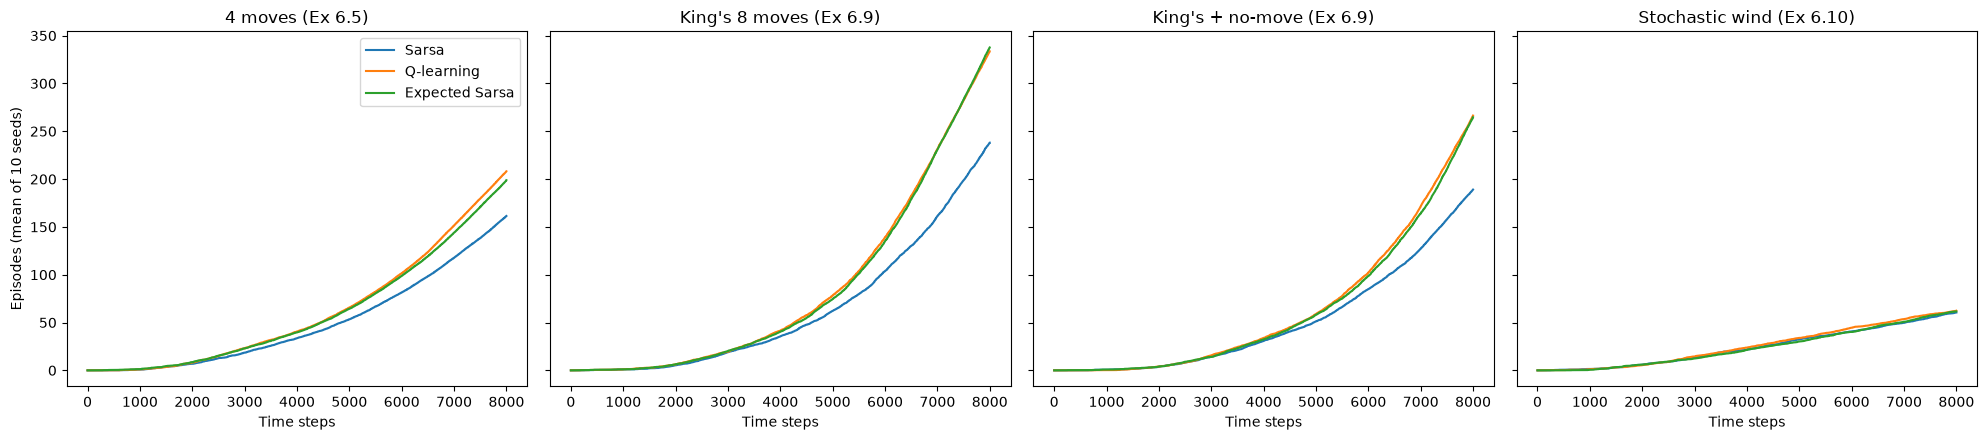

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, env_name in zip(axes, ENVS):
    for algo, label in ALGOS.items():
        ax.plot(results[(env_name, algo)][0], label=label)
    ax.set_title(env_name); ax.set_xlabel('Time steps')
axes[0].set_ylabel(f'Episodes (mean of {N_SEEDS} seeds)'); axes[0].legend()
plt.tight_layout(); plt.savefig('figures/windy_learning_curves.png', dpi=130); plt.show()

def draw_path(ax, Q, step, title, seed=0):
    path = greedy_path(Q, step, np.random.default_rng(seed))
    ax.set_xlim(-0.5, COLS - 0.5); ax.set_ylim(ROWS - 0.5, -0.5)
    ax.set_xticks(np.arange(-0.5, COLS), minor=True); ax.set_yticks(np.arange(-0.5, ROWS), minor=True)
    ax.grid(which='minor'); ax.set_xticks([]); ax.set_yticks([])
    for c, w in enumerate(WIND):
        ax.text(c, ROWS - 0.15, str(w), ha='center', va='top', fontsize=10, clip_on=False)
    ax.text(START[1], START[0], 'S', ha='center', va='center', fontsize=14, weight='bold')
    ax.text(GOAL[1], GOAL[0], 'G', ha='center', va='center', fontsize=14, weight='bold')
    for (r1, c1), (r2, c2) in zip(path[:-1], path[1:]):
        ax.annotate('', xy=(c2, r2), xytext=(c1, r1), arrowprops=dict(arrowstyle='->', color='blue', lw=2))
    status = f'{len(path) - 1} steps' if path[-1] == GOAL else 'did not reach G in 100 steps'
    ax.set_title(f'{title}\n(greedy path: {status})', fontsize=10)

8,000 스텝만 학습니까 Sarsa의 greedy 정책이 일부 시드에서 G에 도착하지 못했다. 그래서 30,000 스텝까지 학습한 뒤의 결과도 비교했다 (시드 5개).

In [6]:
LONG_STEPS, LONG_SEEDS = 30_000, 5
long_results = {}
t0 = time.time()
for env_name, (step, n_actions) in ENVS.items():
    for algo in ALGOS:
        ep_len, greedy_len, Qs = [], [], []
        for seed in range(LONG_SEEDS):
            Q, hist = train(step, n_actions, algo, seed, max_steps=LONG_STEPS)
            ep_len.append(5000 / max(hist[-1] - hist[-5001], 1))
            g = np.random.default_rng(2000 + seed)
            for _ in range(200 if 'Stochastic' in env_name else 1):
                path = greedy_path(Q, step, g)
                greedy_len.append(len(path) - 1 if path[-1] == GOAL else np.nan)
            Qs.append(Q)
        gl = np.array(greedy_len)
        long_results[(env_name, algo)] = (np.mean(ep_len), np.nanmean(gl), np.mean(~np.isnan(gl)) * 100, Qs[0])
print(f'done in {time.time()-t0:.1f}s\n')
print(f"{'environment':28s} {'algorithm':15s} {'eps-greedy ep len (last 5k)':>28s} {'greedy len (mean)':>18s} {'reach G':>8s}")
for (env_name, algo), (el, gl, ok, _) in long_results.items():
    print(f'{env_name:28s} {ALGOS[algo]:15s} {el:28.1f} {gl:18.1f} {ok:7.0f}%')

done in 38.9s

environment                  algorithm        eps-greedy ep len (last 5k)  greedy len (mean)  reach G
4 moves (Ex 6.5)             Sarsa                                   20.0               16.0      80%
4 moves (Ex 6.5)             Q-learning                              17.2               15.0     100%
4 moves (Ex 6.5)             Expected Sarsa                          17.1               15.0     100%
King's 8 moves (Ex 6.9)      Sarsa                                   10.6                7.8     100%
King's 8 moves (Ex 6.9)      Q-learning                               9.3                7.0     100%
King's 8 moves (Ex 6.9)      Expected Sarsa                           8.3                7.0     100%
King's + no-move (Ex 6.9)    Sarsa                                   10.4                7.8     100%
King's + no-move (Ex 6.9)    Q-learning                               9.4                7.0     100%
King's + no-move (Ex 6.9)    Expected Sarsa                        

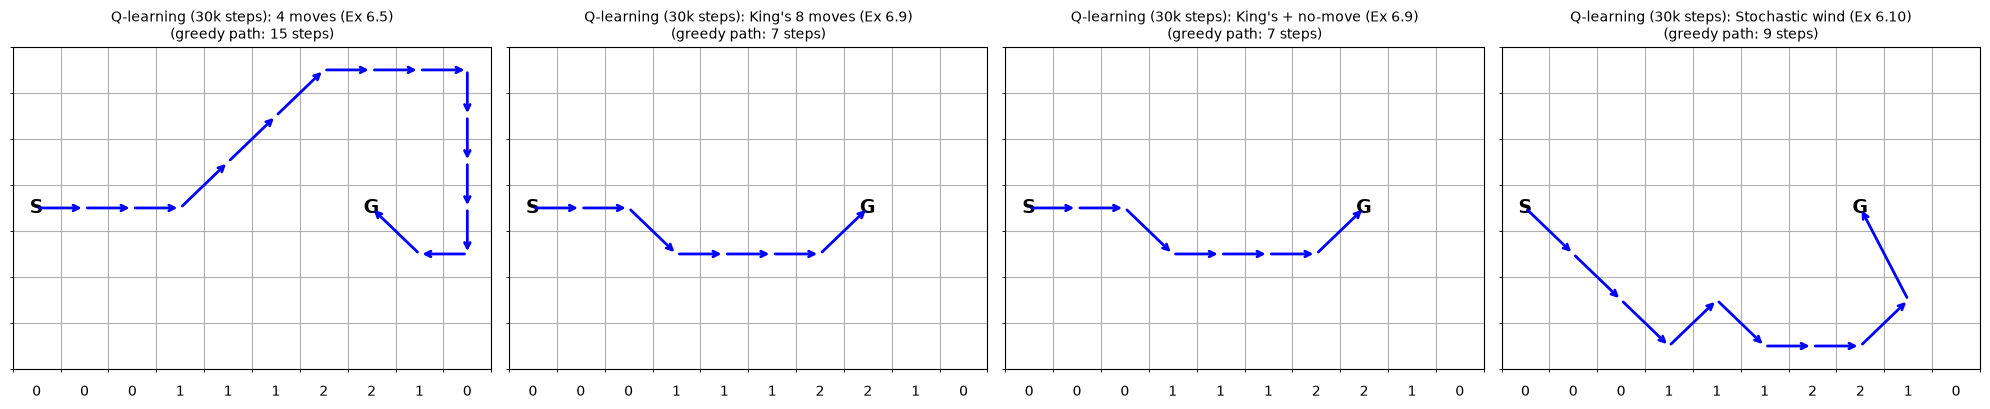

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
for ax, env_name in zip(axes, ENVS):
    step, _ = ENVS[env_name]
    draw_path(ax, long_results[(env_name, 'q_learning')][3], step, f'Q-learning (30k steps): {env_name}', seed=3)
plt.tight_layout(); plt.savefig('figures/windy_greedy_paths.png', dpi=130); plt.show()

**Exercise 6.9**: Windy Gridworld with King's Moves. How much better can you do with the extra actions? Can you do even better by including a ninth action that causes no movement at all other than that caused by the wind?

대각선 이동을 넣었더니 최적 경로가 15 스텝에서 7 스텝으로 절반 이하가 된다. 반면, 9번째 행동은 도움이 되지 않았다. 오히려 행동이 하나 늘어 탐험할 게 많아져서 초반 학습이 느려졌다.

---

**Exercise 6.10**

바람을 무작위로 흔들리는 조건을 넣었더니 같은 행동을 해도 결과가 달라져서 훨씬 어려워졌다. 8,000 스텝 동안 끝낸 에피소드가 334개 에서 약 60개로 줄었고, 30,000 스텝 학습 후에도 ε-greedy 평균 에피소드 길이가 고정이였을 대비의 거의 4배인 35–40 스텝이다. greedy 경로도 100 스텝 안에 G에 도착하는 비율이 41–60%뿐이었다.

알고리즘끼리는 차이가 작았다. ε-greedy로 실제 움직일 때의 에피소드 길이는 Sarsa가 가장 짧았고(35.2), greedy 경로는 Q-learning이 가장 짧았다(14.7). Sarsa는 탐험과 바람의 위험까지 가치에 반영해 안전한 정책을, Q-learning은 탐험이 없다고 가정한 최단 경로를 배우기 때문이다.

---

**Example 6.6: Cliff Walking** (교재 p.132)

- 4×12 격자, 시작 (3,0), 목표 (3,11), 아래쪽 (3,1)–(3,10)이 절벽
- 매 스텝 −1, 절벽에 떨어지면 −100을 받고 시작점으로
- ε = 0.1, α = 0.5, 500 에피소드, 에피소드당 보상 합을 50 run 평균

**구현 방법**: Figure 6.4는 x축이 에피소드라서, time step 기준인 `train` 대신 에피소드마다 보상 합을 기록하는 함수를 따로 만들었다. target 계산 규칙은 위와 같다.

done in 40.0s
Sarsa          : mean reward per episode (episodes 400-500) = -26.7
Q-learning     : mean reward per episode (episodes 400-500) = -49.7
Expected Sarsa : mean reward per episode (episodes 400-500) = -20.3


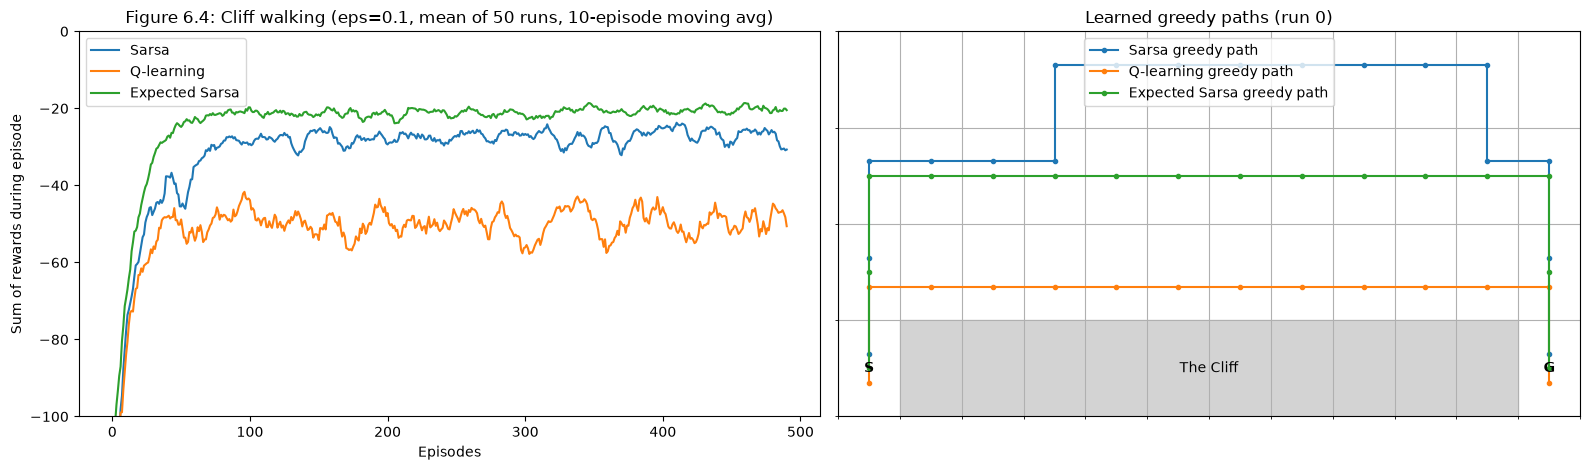

In [9]:
C_ROWS, C_COLS = 4, 12
C_START, C_GOAL = (3, 0), (3, 11)

def cliff_step(state, action, rng=None):
    dr, dc = MOVES_4[action]
    r = int(np.clip(state[0] + dr, 0, C_ROWS - 1)); c = int(np.clip(state[1] + dc, 0, C_COLS - 1))
    if r == 3 and 1 <= c <= 10:                 # 절벽
        return C_START, -100.0
    return (r, c), -1.0

def cliff_train(algorithm, seed, n_episodes=500, eps=EPSILON):
    rng = np.random.default_rng(seed)
    Q = np.zeros((C_ROWS, C_COLS, 4))
    rewards = np.zeros(n_episodes)
    for e in range(n_episodes):
        state = C_START
        if algorithm == 'sarsa':
            action = epsilon_greedy(Q[state], eps, rng)
        while state != C_GOAL:
            if algorithm != 'sarsa':
                action = epsilon_greedy(Q[state], eps, rng)
            next_state, reward = cliff_step(state, action)
            rewards[e] += reward
            if algorithm == 'sarsa' and next_state != C_GOAL:
                next_action = epsilon_greedy(Q[next_state], eps, rng)
            if next_state == C_GOAL:
                target = reward
            elif algorithm == 'sarsa':
                target = reward + GAMMA * Q[next_state][next_action]
            elif algorithm == 'q_learning':
                target = reward + GAMMA * Q[next_state].max()
            else:
                target = reward + GAMMA * expected_q(Q[next_state], eps)
            Q[state][action] += ALPHA * (target - Q[state][action])
            state = next_state
            if algorithm == 'sarsa' and state != C_GOAL:
                action = next_action
    return Q, rewards

CLIFF_RUNS = 50
cliff = {}
t0 = time.time()
for algo in ALGOS:
    runs = [cliff_train(algo, s) for s in range(CLIFF_RUNS)]
    cliff[algo] = (np.mean([r for _, r in runs], axis=0), runs[0][0])
print(f'done in {time.time()-t0:.1f}s')
for algo, label in ALGOS.items():
    print(f'{label:15s}: mean reward per episode (episodes 400-500) = {cliff[algo][0][400:].mean():.1f}')

def smooth(x, w=10):
    return np.convolve(x, np.ones(w) / w, mode='valid')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for algo, label in ALGOS.items():
    axes[0].plot(smooth(cliff[algo][0]), label=label)
axes[0].set_ylim(-100, 0); axes[0].set_xlabel('Episodes'); axes[0].set_ylabel('Sum of rewards during episode')
axes[0].set_title(f'Figure 6.4: Cliff walking (eps=0.1, mean of {CLIFF_RUNS} runs, 10-episode moving avg)')
axes[0].legend()

ax = axes[1]
ax.set_xlim(-0.5, C_COLS - 0.5); ax.set_ylim(C_ROWS - 0.5, -0.5)
ax.set_xticks(np.arange(-0.5, C_COLS), minor=True); ax.set_yticks(np.arange(-0.5, C_ROWS), minor=True)
ax.grid(which='minor'); ax.set_xticks([]); ax.set_yticks([])
ax.fill_between([0.5, 10.5], 2.5, 3.5, color='lightgray')
ax.text(5.5, 3, 'The Cliff', ha='center', va='center')
for algo, color, off in [('sarsa', 'tab:blue', -0.15), ('q_learning', 'tab:orange', 0.15), ('expected_sarsa', 'tab:green', 0.0)]:
    Q = cliff[algo][1]; s, path = C_START, [C_START]
    for _ in range(60):
        if s == C_GOAL: break
        s, _ = cliff_step(s, int(np.argmax(Q[s]))); path.append(s)
    ax.plot([p[1] for p in path], [p[0] + off for p in path], '-o', color=color, ms=3, label=f'{ALGOS[algo]} greedy path')
ax.text(0, 3, 'S', ha='center', va='center', weight='bold'); ax.text(11, 3, 'G', ha='center', va='center', weight='bold')
ax.legend(loc='upper center'); ax.set_title('Learned greedy paths (run 0)')
plt.tight_layout(); plt.savefig('figures/cliff_walking.png', dpi=130); plt.show()

**결과 해석**

오른쪽 그림에서 Q-learning은 절벽 바로 옆 최단 경로(13스텝), Expected Sarsa는 절벽에서 한 줄 떨어진 경로(15스텝), Sarsa는 맨 위 줄까지 돌아가는 경로(17스텝)를 배웠다. 최단 경로를 배운 Q-learning이 오히려 탐험 중 절벽에 자주 떨어져 에피소드당 보상이 가장 낮았고(−49.7), 위험을 반영하면서 너무 멀리 돌아가지 않는 Expected Sarsa가 가장 높았다(−20.3).

---

**Exercise 6.11**

Q-learning은 실제로 움직일 때는 ε-greedy 정책을 따르지만, 업데이트할 때는 target에 $\max_a Q(S',a)$, 즉 다음 상태에서 가장 좋은 행동을 한다고 가정한 greedy 정책의 가치를 쓴다. 데이터를 만드는 정책과 학습하는 정책이 다르기 때문에 off-policy이다.

---

**Exercise 6.12**

정확히 같지는 않다. Sarsa는 $A'$을 $Q(S,A)$ 업데이트 전에 고르고, 다음 스텝에 그대로 실행한다. Q-learning은 $Q(S,A)$를 업데이트한 뒤에 다음 상태에서 행동을 새로 고른다. 그 결과 Sarsa는 업데이트 전 기준, Q-learning은 업데이트 후 기준으로 행동해서 결과가 달라진다.

